# CCF estimators on a generator with known truth: which reference date biases the EAD

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic (the factor, its designs and its treatments)
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- read the six acceleration levels of the C09 generator and say what its known CCF is at each;
- explain the two aggregations of a set of factors, the mean and the pooled ratio, and why they differ when the lines with the most undrawn amount draw least;
- compute the bias of an estimator against the known truth with `ccf_bias`, read `ccf_estimator_bias` (statistic, p-value, tolerance and light) and say why a significant bias inside the tolerance stays green;
- compare the three reference-date designs and the four treatments of a factor outside [0, 1] on the committed replications, at each level, and say how much of the result is a property of the generator's own horizon;
- fit the two EAD models that need no factor, `fit_direct_ead` and `fit_utilisation_change`, and see why the first cannot predict above the limit.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import ccf
from riskvalidation.validation import lgd_ead as lgd_tests

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Seven committed artifacts of case C09, the exposure at default of revolving credit lines: the generator artifact `models-generator.json` and the variants `level-0.json` to `level-5.json`, one per acceleration level. C09 has **a known truth**: its lines are produced by a generator whose marginal distributions follow the Federal Reserve's 2025 hypothetical card portfolios, and whose conversion factor is its own parameter. At level 0 the undrawn amount is drawn at a constant rate over the twelve months before the default. From level 1 on, the drawing rate accelerates in the last six months by a factor of 1.25 up to 3, which raises the known CCF, because the balance rises faster near the default.

Each level is evaluated on 20 development and 20 test replications of 50,000 facilities with fixed seeds, so every estimate in the artifacts is the mean over 20 independent replications, shown with its bias against the truth, its RMSE and a confidence interval. The data are synthetic and say nothing about any lender. The artifacts were baked by an older engine than the installed one, and the next cell prints both versions.

In [2]:
# Load the generator artifact and the six levels; print the levels, the replication plan, the designs and the versions
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C09"
gen = json.loads((DERIVED / "models-generator.json").read_text(encoding="utf-8"))["fit"]
levels = [json.loads((DERIVED / f"level-{i}.json").read_text(encoding="utf-8")) for i in range(6)]
print("baked by riskvalidation:", sorted({v["provenance"]["riskvalidation_version"] for v in levels}), "| installed:", rv.__version__)
plan = gen["replications_plan"]
print(f"replications: {len(plan['development_seeds'])} development + {len(plan['test_seeds'])} test | facilities per replication: {plan['n_facilities']:,}")
print()
print(f"{'level':>6s} {'acceleration factor':>26s} {'window (months)':>20s} {'known CCF':>14s}")
for lv, doc in zip(gen["levels"], levels):
    print(f"{lv['level']:6d} {lv['acceleration_factor']:26.2f} {lv['acceleration_window_months']:20d} {doc['outputs']['generator']['true_ccf']['value']:14.6f}")
print()
for design in gen["designs"]:
    print("-", design["label"]["en"])
TREAT = {"none": "none", "censor": "censor", "floor-cap": "floor-cap", "bounded-scale": "bounded-scale"}
print("treatments:", ", ".join(TREAT[t] for t in gen["treatments"]))

baked by riskvalidation: ['1.0.1'] | installed: 1.0.1
replications: 20 development + 20 test | facilities per replication: 50,000

 level        acceleration factor      window (months)      known CCF
     0                       1.00                    0       0.600000
     1                       1.25                    6       0.634252
     2                       1.50                    6       0.664272
     3                       2.00                    6       0.714173
     4                       2.50                    6       0.753697
     5                       3.00                    6       0.785540

- Fixed horizon: 12 months before default
- Yearly cohort: the cohort start
- Variable horizon: quarterly reference dates in the year before default
treatments: none, censor, floor-cap, bounded-scale


## Method

### Step 1: two ways to combine the factors

Given the factors $c_i$ of $N$ defaulters and their undrawn amounts $U_i = L_i - E_i$ at the reference date, the engine's `aggregate_ccf(ccf, undrawn, aggregator)` offers two summaries:

$$\text{mean} = \frac{1}{N}\sum_i c_i, \qquad \text{pooled} = \frac{\sum_i c_i\,U_i}{\sum_i U_i} = \frac{\sum_i (EAD_i - E_i)}{\sum_i (L_i - E_i)}$$

(Source: the docstring of `aggregate_ccf`; undefined factors are excluded and a set with no defined factor raises an error.) The mean gives every defaulter the same weight; the pooled ratio gives every unit of undrawn amount the same weight, so it is the share of the undrawn *currency* that was drawn. The two differ when the factor depends on the size of the undrawn amount. The cell invents six defaulters, three with a small undrawn amount that draw it all and three with a large one that draw little, and prints both.

In [3]:
# Six invented defaulters: small undrawn amounts drawn fully, large ones drawn little; the mean and the pooled ratio
factor = np.array([1.0, 1.0, 1.0, 0.2, 0.2, 0.2])
undrawn = np.array([10.0, 10.0, 10.0, 1_000.0, 1_000.0, 1_000.0])
mean_c = ccf.aggregate_ccf(factor, undrawn, "mean")
pooled_c = ccf.aggregate_ccf(factor, undrawn, "pooled")
print(f"mean = {mean_c:.4f} | pooled = {pooled_c:.4f}")
print(f"pooled by hand: sum(c * U) / sum(U) = {np.sum(factor * undrawn):.1f} / {np.sum(undrawn):.1f} = {np.sum(factor * undrawn) / np.sum(undrawn):.4f}")

mean = 0.6000 | pooled = 0.2079
pooled by hand: sum(c * U) / sum(U) = 630.0 / 3030.0 = 0.2079


### Step 2: the bias of an estimator and its test

A generator knows the true CCF, so an estimator can be scored: `ccf_bias(estimate, truth)` is $\text{estimate} - \text{truth}$, signed and not clipped. C09 repeats the experiment $R = 20$ times and the engine's `ccf_estimator_bias(estimates, truth, tolerance)` summarises the replications. With $e_r = \hat c_r - c$ the error of replication $r$:

$$\text{bias} = \bar e, \qquad \text{RMSE} = \sqrt{\overline{e^2}}, \qquad t = \frac{\bar e}{s_e/\sqrt{R}} \; (R - 1 \text{ degrees of freedom}), \qquad p = 2\,P(T_{R-1} > |t|)$$

The light depends only on the bias and a tolerance, not on the p-value: green when $|\text{bias}| \le$ tolerance, amber up to twice it, red above; the p-value is informative, so a statistically significant bias inside the tolerance stays green and the view shows both (all from the function's docstring, a Contraste internal gate and not a regulatory one). The C09 tolerance is 0.02.

The next cell invents the 20 estimates of two estimators against a truth of 0.6: one with a small and steady bias of -0.015, which is significant and inside the tolerance, and one with a bias of -0.05. These 40 numbers are made up to show how the test reads.

In [4]:
# Score two invented estimators against a known truth of 0.6 with a tolerance of 0.02
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
rng = np.random.default_rng(11)
truth = 0.6
steady = truth - 0.015 + rng.normal(0.0, 0.004, 20)
poor = truth - 0.05 + rng.normal(0.0, 0.02, 20)
for label, est in (("steady, bias -0.015", steady), ("poor, bias -0.05", poor)):
    res = lgd_tests.ccf_estimator_bias(est, truth, tolerance=0.02, model_id=label)
    print(f"{label:34s} bias {res.metric:8.4f} (ccf_bias: {ccf.ccf_bias(est.mean(), truth):8.4f}) t={res.statistic:8.3f} p={res.p_value:.2e} RMSE={res.extras['rmse']:.4f} within tolerance={res.extras['within_tolerance']} light: {LIGHT[res.light.value]}")

steady, bias -0.015                bias  -0.0142 (ccf_bias:  -0.0142) t= -19.980 p=3.24e-14 RMSE=0.0145 within tolerance=True light: green
poor, bias -0.05                   bias  -0.0572 (ccf_bias:  -0.0572) t= -15.166 p=4.54e-12 RMSE=0.0595 within tolerance=False light: red


### Step 3: the committed biases, level by level

Each level variant holds `outputs.ccf_by_design.rows`, 24 rows: three designs, four treatments and two aggregations, each with the estimate (the mean over the 20 test replications), the bias against the truth, the RMSE, the confidence interval and the number of defaulters used. The cell selects the four untreated rows that matter most, `fixed-horizon` with the mean and with the pooled ratio, and `cohort` and `variable-horizon` with the pooled ratio, and the cohort and variable-horizon rows with the mean. It recomputes each bias with `ccf_bias` from the committed estimate and truth, and prints the largest difference against the committed bias, which tests the artifact against the engine's definition.

In [5]:
# Recompute the bias of six untreated estimators at each level with ccf_bias and compare with the committed bias
KEYS = [("fixed-horizon", "mean"), ("fixed-horizon", "pooled"), ("cohort", "mean"), ("cohort", "pooled"), ("variable-horizon", "mean"), ("variable-horizon", "pooled")]
DESIGN = {"fixed-horizon": "fixed", "cohort": "cohort", "variable-horizon": "variable"}
AGG = {"mean": "mean", "pooled": "pooled"}
header = " ".join(f"{DESIGN[d] + ' ' + AGG[a]:>16s}" for d, a in KEYS)
print(f"{'level':>5s} {'known CCF':>12s} " + header)
biases = {k: [] for k in KEYS}
rmses = {k: [] for k in KEYS}
largest = 0.0
for i, doc in enumerate(levels):
    truth_i = doc["outputs"]["generator"]["true_ccf"]["value"]
    rows = {(r["design"], r["treatment"], r["estimator"]): r for r in doc["outputs"]["ccf_by_design"]["rows"]}
    line = []
    for key in KEYS:
        row = rows[(key[0], "none", key[1])]
        recomputed = ccf.ccf_bias(row["estimate"]["value"], truth_i)
        largest = max(largest, abs(recomputed - row["bias"]))
        biases[key].append(recomputed)
        rmses[key].append(row["rmse"])
        line.append(f"{recomputed:16.4f}")
    print(f"{i:5d} {truth_i:12.4f} " + " ".join(line))
print(f"largest difference between ccf_bias and the committed bias: {largest:.2e} | tolerance: {levels[0]['outputs']['ccf_by_design']['tolerance']}")
print()
print("RMSE over the 20 replications")
for i in range(6):
    print(f"{i:5d} {'':12s} " + " ".join(f"{rmses[key][i]:16.4f}" for key in KEYS))

level    known CCF       fixed mean     fixed pooled      cohort mean    cohort pooled    variable mean  variable pooled
    0       0.6000          -0.0017          -0.0205           0.0823          -0.2579           0.3099          -0.1815
    1       0.6343          -0.0016          -0.0204          -0.1043          -0.2487           0.0032          -0.1729
    2       0.6643          -0.0015          -0.0201          -0.0490          -0.2397           0.4848          -0.1649
    3       0.7142          -0.0014          -0.0193           0.0555          -0.2230           0.0728          -0.1503
    4       0.7537          -0.0013          -0.0183           0.0149          -0.2080           0.1059          -0.1377
    5       0.7855          -0.0011          -0.0173           0.3448          -0.1945           0.2678          -0.1268
largest difference between ccf_bias and the committed bias: 3.00e-09 | tolerance: 0.02

RMSE over the 20 replications
    0                        0.0072

### Step 4: the same table, drawn

The figure plots the pooled-ratio bias of the three designs against the acceleration level, with the tolerance band of plus and minus 0.02. It uses the pooled ratio because the table above shows why the mean cannot be read for the cohort and variable-horizon designs: its bias jumps from level to level and its RMSE runs from 0.1116 to 2.3102 across the levels, while the RMSE of the pooled ratio runs from 0.1280 to 0.2583, since a ratio with a small undrawn amount in the denominator is unbounded and a few such lines dominate an unweighted mean. A design inside the band is green; a design far below it systematically under-reads the known CCF.

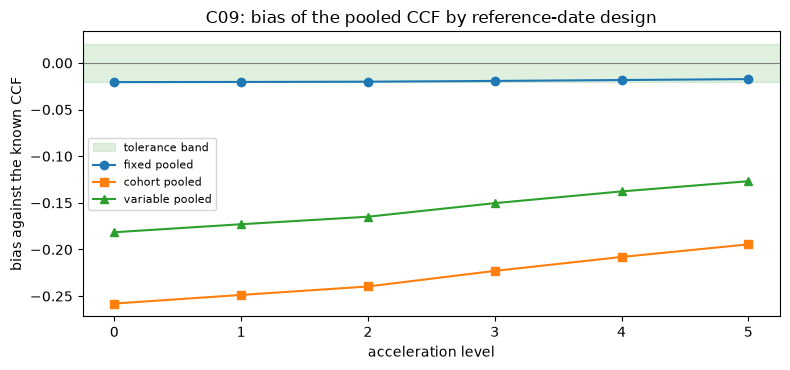

In [6]:
# Draw the pooled-ratio bias of the three designs against the acceleration level, with the tolerance band
fig, ax = plt.subplots(figsize=(8, 3.8))
tolerance = levels[0]["outputs"]["ccf_by_design"]["tolerance"]
ax.axhspan(-tolerance, tolerance, color="tab:green", alpha=0.15, label="tolerance band")
for design, marker in (("fixed-horizon", "o"), ("cohort", "s"), ("variable-horizon", "^")):
    ax.plot(range(6), biases[(design, "pooled")], marker=marker, label=f"{DESIGN[design]} pooled")
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("acceleration level")
ax.set_ylabel("bias against the known CCF")
ax.set_title("C09: bias of the pooled CCF by reference-date design")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

One caution before reading the figure as a ranking. The generator defines its known CCF over the twelve months before the default, which is exactly the horizon of the `fixed-horizon` design. That design therefore measures the quantity the truth is defined for, and its near-zero bias is partly by construction. The cohort and variable-horizon designs put the reference date later and measure the share of a smaller undrawn amount, so against this truth they read low. What the figure shows is how large the gap between designs is on the same defaults, not that one design is correct in general.

### Step 5: the treatments of a factor outside [0, 1]

Notebook 02 introduced the four treatments of `treat_ccf`. Here is what each does to the bias, at level 3, with the fixed-horizon design and both aggregations. `censor` drops the observations outside [0, 1], which removes the lines that drew more than their undrawn amount and so pulls the estimate down; `floor-cap` clips them, which the engine documents as biasing the EAD; `bounded-scale` is the fractional-logit response on the clipped values. The cell prints, for each treatment, the number of defaulters used, the estimate, the bias and whether it is inside the tolerance.

In [7]:
# Print the four treatments of the fixed-horizon design at level 3, with both aggregations
doc3 = levels[3]["outputs"]
print("level 3, known CCF:", doc3["generator"]["true_ccf"]["value"], "|", levels[3]["outputs"]["level_description"]["en"])
print(f"{'treatment':18s} {'aggregation':>14s} {'defaulters':>14s} {'estimate':>12s} {'bias':>9s} {'inside the tolerance':>26s}")
for r in doc3["ccf_by_design"]["rows"]:
    if r["design"] == "fixed-horizon":
        print(f"{TREAT[r['treatment']]:18s} {AGG[r['estimator']]:>14s} {r['n_defaults']:14,d} {r['estimate']['value']:12.4f} {r['bias']:9.4f} {bool(r['within_tolerance'])!s:>26s}")
r0 = next(r for r in doc3["ccf_by_design"]["rows"] if r["design"] == "fixed-horizon" and r["treatment"] == "none")
r_censor = next(r for r in doc3["ccf_by_design"]["rows"] if r["design"] == "fixed-horizon" and r["treatment"] == "censor")
print(f"defaulters dropped by censoring: {r0['n_defaults'] - r_censor['n_defaults']:,}")
print(f"share of factors below 0: {r0['share_below_zero']:.4f} | above 1: {r0['share_above_one']:.4f}")

level 3, known CCF: 0.714173169 | Level 3: in the last 6 months before default the drawing rate is 2 times its earlier rate.
treatment             aggregation     defaulters     estimate      bias       inside the tolerance
none                         mean         30,154       0.7128   -0.0014                       True
none                       pooled         30,154       0.6949   -0.0193                       True
censor                       mean         25,691       0.6584   -0.0558                      False
censor                     pooled         25,691       0.6453   -0.0689                      False
floor-cap                    mean         30,154       0.7002   -0.0140                       True
floor-cap                  pooled         30,154       0.6839   -0.0303                      False
bounded-scale                mean         30,154       0.7013   -0.0129                       True
bounded-scale              pooled         30,154       0.6887   -0.0254            

### Step 6: the committed tests

The engine's `ccf_estimator_bias` ran on each estimator's 20 replications at bake time, and the artifact keeps its rows in `tests`: statistic, p-value, the bias as metric, the RMSE and interval, the tolerance and the light. The cell prints the rows of four of the untreated estimators of step 3 at level 3 and, for the whole set of 24 estimators of that level, how many are green, amber and red. The tests were produced by the engine version printed in the Data section, so they are read as baked, not recomputed.

In [8]:
# Print the committed ccf_estimator_bias rows of four estimators at level 3 and the count of lights over the 24 estimators
tests = [t for t in levels[3]["tests"] if t["test_id"] == "lgd_ead.ccf_estimator_bias"]
print("tests baked by riskvalidation:", levels[3]["provenance"]["riskvalidation_version"], "|", len(tests), "estimators")
for model_id in ("ccf-fixed-horizon-none-mean", "ccf-fixed-horizon-none-pooled", "ccf-cohort-none-pooled", "ccf-variable-horizon-none-pooled"):
    t = next(t for t in tests if t["model_id"] == model_id)
    print(f"{model_id:34s} bias {t['metric']:8.4f}  t={t['statistic']:8.2f}  p={t['p_value']:.2e}  RMSE={t['extras']['rmse']:.4f}  light: {LIGHT[t['light']]}")
counts = {}
for t in tests:
    counts[t["light"]] = counts.get(t["light"], 0) + 1
print({LIGHT[k]: v for k, v in counts.items()})

tests baked by riskvalidation: 1.0.1 | 24 estimators
ccf-fixed-horizon-none-mean        bias  -0.0014  t=   -0.85  p=4.07e-01  RMSE=0.0073  light: green
ccf-fixed-horizon-none-pooled      bias  -0.0193  t=   -5.63  p=1.99e-05  RMSE=0.0244  light: green
ccf-cohort-none-pooled             bias  -0.2230  t=  -61.65  p=2.38e-23  RMSE=0.2235  light: red
ccf-variable-horizon-none-pooled   bias  -0.1503  t=  -39.70  p=9.56e-20  RMSE=0.1512  light: red
{'green': 4, 'red': 18, 'amber': 2}


### Step 7: EAD models without a factor

The research asks whether a model of the EAD itself, with no factor, does better than the factor (Tong et al. 2016, as the engine's docstring names it). The engine fits two:

- `fit_direct_ead(X, ead, limit)`: a fractional logit of $EAD / L$ on the covariates. An EAD above the limit gives a ratio above 1; it is clipped to 1 for the fit and **counted** in `extras`, never silently. The engine notes that the zero-adjusted gamma mixture of Tong et al. (2016) is not in this version.
- `fit_utilisation_change(X, drawn_ref, drawn_default, limit_ref)`: least squares on the change of utilisation $(E(t_d) - E(t_r)) / L(t_r)$, which has no undrawn amount in the denominator.

`predict_ead` returns for the first $L$ times the fitted ratio, inside $[0, L]$, and for the second $E(t_r) + L\,\hat\Delta$, not clipped. The next cell shows both on a **toy** sample generated in the notebook (3,000 lines, a known factor of 0.6, a noise that sends some lines over their limit), because the loan-level lines of C09 are generated by the pipeline and not committed. It prints the covariate counts that the committed artifact reports for the real fit.

In [9]:
# Fit the two factor-free EAD models on a toy sample with a known factor, and read the committed fit counts
rng = np.random.default_rng(7)
n = 3000
limit_toy = np.exp(rng.normal(8.5, 0.8, n))
util = rng.beta(0.8, 1.8, n) * 0.99
drawn_ref = util * limit_toy
ead_toy = drawn_ref + 0.6 * (limit_toy - drawn_ref) + rng.normal(0.0, 0.08, n) * limit_toy
Xe = np.column_stack([np.ones(n), util, np.log(limit_toy)])
cols = ("const", "utilisation", "log_limit")
direct = ccf.fit_direct_ead(Xe, ead_toy, limit_toy, cols)
change = ccf.fit_utilisation_change(Xe, drawn_ref, ead_toy, limit_toy, cols)
pred_direct = ccf.predict_ead(direct, Xe, drawn_ref, limit_toy)
pred_change = ccf.predict_ead(change, Xe, drawn_ref, limit_toy)
print(f"toy lines: {n:,} | realised EAD above the limit: {int((ead_toy > limit_toy).sum())} | clipped for the direct fit (counted by the engine): {direct.extras['n_clipped_above']}")
print(f"mean realised EAD: {ead_toy.mean():,.1f} | direct: {pred_direct.mean():,.1f} | utilisation change: {pred_change.mean():,.1f}")
print(f"predictions above the limit: direct {int((pred_direct > limit_toy).sum())} | utilisation change {int((pred_change > limit_toy).sum())} | largest realised EAD over limit: {np.max(ead_toy / limit_toy):.3f}")
print()
for m in levels[3]["outputs"]["ead_models"]:
    if m["kind"] in ("direct-ead", "utilisation-change"):
        print(f"committed fit at level 3: {m['model_id']:20s} covariates {m['covariates']} clipped below {m['n_clipped_below']} clipped above {m['n_clipped_above']}")

toy lines: 3,000 | realised EAD above the limit: 49 | clipped for the direct fit (counted by the engine): 49
mean realised EAD: 4,750.4 | direct: 4,746.1 | utilisation change: 4,750.9
predictions above the limit: direct 0 | utilisation change 0 | largest realised EAD over limit: 1.164

committed fit at level 3: direct-ead           covariates ['utilisation', 'log_limit', 'credit_score'] clipped below 0 clipped above 12913
committed fit at level 3: utilisation-change   covariates ['utilisation', 'log_limit', 'credit_score'] clipped below None clipped above None


## Results

- **The truth moves with the acceleration.** The known CCF is 0.6000 at level 0 and rises to 0.7855 at level 5, as the drawing rate in the last six months goes from 1 to 3 times its earlier rate.
- **The mean and the pooled ratio are different summaries.** On the six invented defaulters the mean is 0.6000 and the pooled ratio 0.2079 (630.0 over 3,030.0), because the three lines with a large undrawn amount draw little.
- **The test reads the bias, and the light reads the tolerance.** On the invented estimators, the steady one has a bias of -0.0142, a t statistic of -19.980 and a p-value of 3.24e-14, and stays green because it is inside the tolerance of 0.02; the poor one, at -0.0572, is red.
- **The fixed twelve-month design is near unbiased, and that is partly by construction.** Its mean-of-factors bias runs from -0.0017 to -0.0011 and its pooled bias from -0.0205 (level 0, just outside the tolerance of 0.02) to -0.0173. The generator defines its CCF over the same twelve months.
- **Later reference dates read low.** The pooled bias of the cohort design is -0.2579 at level 0 and -0.1945 at level 5, and that of the variable-horizon design -0.1815 and -0.1268: a reference date nearer the default measures the share of a smaller undrawn amount. The gap narrows as the acceleration grows. The bias of the mean of factors for those two designs is erratic (cohort from -0.1043 to 0.3448, variable-horizon from 0.0032 to 0.4848) and its RMSE reaches 2.3102, so only the pooled ratio can be read.
- **Treatments matter.** At level 3, censoring the factors outside [0, 1] moves the fixed-horizon bias to -0.0558 (mean) and -0.0689 (pooled) and drops 4,463 of the 30,154 defaulters; flooring and capping gives -0.0140 and -0.0303, and the bounded scale -0.0129 and -0.0254. The shares outside [0, 1] are 0.0088 below 0 and 0.1393 above 1.
- **The committed tests agree.** At level 3, 4 of the 24 estimators are green, 2 amber and 18 red. The fixed-horizon pooled ratio has a p-value of 1.99e-05 and is still green, since its bias of -0.0193 is inside the tolerance; the cohort (t = -61.65) and variable-horizon pooled ratios are red.
- **A direct EAD model counts what it clips.** On the toy sample 49 of 3,000 lines have a realised EAD above their limit (up to 1.164 times it), the direct fit counts the same 49, and no prediction of either model exceeds the limit. The committed level 3 fit clipped 12,913 lines above the limit.

What the notebook does not do: it does not say which design is right for a bank, since the truth here is defined at twelve months and the data are synthetic. The toy sample is generated in the notebook only to show the functions. The next notebook backtests the EAD models by utilisation band.

## Summary

- A generator with a known CCF turns "which design is right?" into a measurement: the bias of each estimator against the truth, over 20 independent replications, with a tolerance.
- The mean and the pooled ratio are different summaries and give different answers when the lines with most undrawn amount draw least; the pooled ratio is the share of undrawn currency drawn.
- The reference date is a design with a cost: later dates read lower against a truth defined at twelve months, by an amount that shrinks as the acceleration rises. The fixed twelve-month design is near unbiased partly because it matches the generator's horizon.
- Treating factors outside [0, 1] moves the estimate; censoring and clipping both bias it, and the bias is reported, not hidden.
- A direct EAD model counts the lines whose EAD exceeds the limit that it must clip, and cannot predict above the limit; the utilisation-change model can.

**What to try next.** Rerun step 3 for the `censor` treatment and compare it with `none`; then continue with notebook 06, which backtests the EAD models by utilisation band and runs the LGD and EAD validation battery.

## References

- Tong, E. N. C., Mues, C., Brown, I. and Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3). https://doi.org/10.1016/j.ejor.2016.01.054
- Qi, M. (2009), Exposure at default of unsecured credit cards, OCC Economics Working Paper 2009-2, as named in the engine's documentation of `riskvalidation.lgd_ead.ccf` and `riskvalidation.validation.lgd_ead`.
- BCBS, Basel Framework, CRE32 (internal ratings-based approach; the supervisory conversion factors). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- The engine's own documentation of `aggregate_ccf`, `ccf_bias`, `fit_direct_ead`, `fit_utilisation_change`, `predict_ead` and `ccf_estimator_bias` (release 0.8.1).
- This repository: `docs/design/SDD.md` (case C09, a generator with a known truth) and `data/derived/C09/`.